In [1]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

Modules to reload:
all-except-skipped

Modules to skip:



In [2]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [3]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [4]:
from unidecode import unidecode
import spacy
from collections import defaultdict
from itertools import chain
nlp = spacy.load('en_core_web_lg', disable=['parser', 'tagger', 'textcat'])

In [5]:
import networkx as nx

In [67]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from  matplotlib.ticker import FuncFormatter

sns.set(style="ticks")
def create_gird(df, col, hue,x,y,sharey=True, legend=False):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette=sns.color_palette("hls", 4),sharey=sharey,
                         col_wrap=5, height=4.5)
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x)))

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)
    if legend:
        grid.add_legend()

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

## Pre-Processing

In [6]:
from ScienceDynamics.datasets.microsoft_academic_graph import MicrosoftAcademicGraph
from ScienceDynamics.config.configs import DATASETS_BASE_DIR
mag = MicrosoftAcademicGraph(DATASETS_BASE_DIR)

In [15]:
papers = mag.extended_papers

In [16]:
papers = papers[papers["Ref Number"]>5]

In [9]:
fields_of_study = mag.papers_fields_of_study_level()

In [17]:
papers = papers.join(fields_of_study, on="PaperId")

In [18]:
papers.save("data/papers.sframe")

In [20]:
paper_ids = papers["PaperId"]

In [11]:
paper_author_aff = mag.paper_author_affiliations

In [21]:
paper_author_aff = paper_author_aff.filter_by(paper_ids,"PaperId")

In [22]:
import geonamescache
gc = geonamescache.GeonamesCache()
cities = gc.get_cities()
countries = gc.get_countries()
cities = {v['name'] for k, v in cities.items()}
countries = {v['name'] for k, v in countries.items()}

In [23]:
import re
paper_author_aff["NormalizedAffiliation"] = paper_author_aff["OriginalAffiliation"].apply(lambda x: set(re.sub(r"[^a-zA-Z0-9]+", ' ', x).split(" ")))

Using default 12 lambda workers.

To maximize the degree of parallelism, add the following code to the beginning of the program:

"turicreate.config.set_runtime_config('TURI_DEFAULT_NUM_PYLAMBDA_WORKERS', 24)"

Note that increasing the degree of parallelism also increases the memory footprint.

In [24]:
paper_author_aff["City_A"] = paper_author_aff["NormalizedAffiliation"].apply(lambda x: set(x)&cities)
paper_author_aff["Country_A"] = paper_author_aff["NormalizedAffiliation"].apply(lambda x: set(x)&countries)

In [25]:
paper_author_aff["City_A"] = paper_author_aff["City_A"].apply(lambda x: x[0] if x else "")
paper_author_aff["Country_A"] = paper_author_aff["Country_A"].apply(lambda x:x[0] if x else "")

In [26]:
from geonamescache.mappers import country
mapper = country(from_key='iso', to_key='name')

In [27]:
paper_author_aff["Country_Temp"] = paper_author_aff.apply(lambda x: gc.get_cities_by_name(x["City_A"]) if x["City_A"] and not x["Country_A"] else [] )

In [28]:
paper_author_aff["Country_Temp"] = paper_author_aff["Country_Temp"].apply(lambda x: [l.popitem()[1] for l in x] )


In [29]:
paper_author_aff["Country_A"] = paper_author_aff.apply(lambda x: x["Country_A"] if x["Country_A"] is not None  else mapper(x["Country_Temp"][0]["countrycode"]) if len(x["Country_Temp"])==1 else "" )

In [30]:
paper_author_aff["AffiliationId"] = paper_author_aff["AffiliationId"].astype(int)

In [32]:
paper_author_aff["City_A"] = paper_author_aff["City_A"].apply(lambda x: None if x=="" else x)
paper_author_aff["Country_A"] = paper_author_aff["Country_A"].apply(lambda x: None if x=="" else x)

In [33]:
paper_author_aff.save("Data/mag/paper_author_aff_1.sframe")

In [30]:
paper_author_aff = load_sframe("Data/mag/paper_author_aff_1.sframe")

In [34]:
affiliations = mag.affiliations

In [35]:
paper_author_aff2 = paper_author_aff.join(affiliations, on={"AffiliationId":"AffiliationId"}, how="left")

In [36]:
paper_author_aff2 = paper_author_aff2[(paper_author_aff2["AffiliationId"]!=None)|(paper_author_aff2["Country_A"]!=None)]

In [37]:
paper_author_aff2["Country"] = paper_author_aff2.apply(lambda x: x["Country_A"] if x["Country"]is None else x["Country"])
paper_author_aff2["City"] = paper_author_aff2.apply(lambda x: x["City_A"] if x["City"] is None else x["City"])

In [38]:
paper_author_aff2 = paper_author_aff2[(paper_author_aff2["Country"]!=None)]

In [39]:
len(paper_author_aff2)

123089906

In [40]:
paper_author_aff2.save("Data/mag/paper_author_aff.sframe")

In [41]:
paper_author_aff = paper_author_aff2

## Author Country

In [39]:
paper_author_aff = load_sframe("Data/mag/paper_author_aff.sframe")

In [42]:
paper_author_aff = paper_author_aff[paper_author_aff["Country"]!=None]

In [43]:
x = paper_author_aff[["PaperId","AuthorId", "Country"]].unstack(["AuthorId", "Country"])

In [44]:
x["num_countries"] = x["Dict of AuthorId_Country"].apply(lambda x: len({v for k,v in x.items() if v!=""  }))

In [45]:
try:
    diseases_mag= diseases_mag.remove_columns(["Dict of AuthorId_Country","num_countries"])
except:
    pass

In [47]:
papers = papers.join(x, on={"PaperId":"PaperId"})

In [48]:
x = paper_author_aff[paper_author_aff["City"]!=None][["PaperId","AuthorId", "City"]].unstack(["AuthorId", "City"])

In [49]:
x["num_cities"] = x["Dict of AuthorId_City"].apply(lambda x: len({v for k,v in x.items() if v!=""  }))

In [53]:
papers = papers.join(x, on={"PaperId":"PaperId"})

In [397]:
try:
    diseases_mag= diseases_mag.remove_columns(["Dict of AuthorId_City","num_cities"])
except:
    pass

In [55]:
papers.save("Data/mag/papers_loc.sframe")

In [50]:
papers = load_sframe("Data/mag/papers_loc.sframe")

In [56]:
papers["Year"] = papers["Year"].astype(int)

In [57]:
papers = papers[papers["num_countries"] > 0]

In [62]:
field_country = papers[["PaperId","Dict of AuthorId_Country","Year","Fields of study parent list names (L2)","num_countries"]].stack("Fields of study parent list names (L2)", new_column_name="Field of Study")

In [63]:
df2 = field_country.groupby(["Field of Study", "Year"],operations={"Average Number of Countries":agg.AVG("num_countries"), "count":agg.COUNT() }).sort("Year",False)

In [64]:
df2 = df2.sort(["Field of Study", "Year"])

In [65]:
df3 = df2[df2["count"] >5]

In [66]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Field of Study"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [75]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/countries.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(df3.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 25), total=((len(des) // 25)+1))):
        create_gird(pd.concat(curr_f),"Field of Study","Field of Study","Year", "Average Number of Countries")
#         plt.title('Page')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

In [417]:
countries_p  = papers.groupby(["Field of Study", "Year"], {"Count": agg.COUNT(),"Freq":agg.FREQ_COUNT("num_countries")})

In [418]:
countries_p["Colab"] = countries_p["Freq"].apply(lambda x: sum([v for k,v in x.items() if k>1]))

In [419]:
countries_p["Colab%"] = countries_p["Colab"] / countries_p["Count"]

In [420]:
countries_p=countries_p.sort(["Field of Study","Year"])

In [422]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Collab/colab_p2.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))

    create_gird(countries_p.to_dataframe(),"Field of Study","Field of Study","Year", "Colab%")
#         plt.title('Page')
    pdf.savefig()
    plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

### Pair Colab

In [76]:
from itertools import combinations
def get_research_cop(diseases_mag, field="Dict of AuthorId_Country", n=2):
    diseases_mag["temp"] = diseases_mag[field].apply(lambda x: [v for v in set(x.values()) if v!=""])
    diseases_mag2 = diseases_mag[diseases_mag["temp"].apply(lambda x: len(x) >= n)]
    diseases_mag2= diseases_mag2[diseases_mag2["temp"]!=None]
    diseases_mag2["temp"] = diseases_mag2["temp"].apply(lambda x: sorted(x))
    diseases_mag2["con_pairs"] = diseases_mag2["temp"].apply(lambda x: list(combinations(x, n)))
    return  diseases_mag2.stack("con_pairs", new_column_name="con_pairs")


In [77]:
papers["countries"] = papers["Dict of AuthorId_Country"].apply(lambda x: [v for v in set(x.values()) if v!=""])

In [424]:
papers = papers.remove_column("temp")

KeyError: 'Cannot find column temp'

In [142]:
field_count = field_country.groupby("Field of Study", agg.COUNT())

In [147]:
field_count

Field of Study,Count
Pasque Flower,1
Blechnum chilense,5
Home management,263
Engleria,1
Perturbation (astronomy),34796
Air embolism,921
Pterogyne,24
Amyl nitrate,11
Runge's theorem,11
Praise,2391


In [148]:
fields = field_count[field_count["Count"]>10000]["Field of Study"]

In [82]:
fields_countries = field_country.stack("countries", new_column_name="country")

# fields_countries_agg = field_country.groupby(["Field of Study","country"],agg.COUNT).sort("Count",False)

KeyError: 'Column Field of Study does not exist in SFrame'

In [506]:
1965 // 10

196

In [510]:
field_country["decade"]  = field_country["Year"]  // 10

In [87]:
fields_countries_agg = get_research_cop(field_country,"Dict of AuthorId_Country", n=1).groupby(["Field of Study","con_pairs"],agg.COUNT).sort("Count",False)

In [504]:
fields_countries_agg

Field of Study,con_pairs,Count,Country
Diabetes mellitus,[United States],2710794,United States
Gene,[United States],1281220,United States
Population,[United States],944069,United States
Cancer,[United States],735614,United States
Cell,[United States],707243,United States
Diabetes mellitus,[United Kingdom],607411,United Kingdom
Enzyme,[United States],560089,United States
Receptor,[United States],536232,United States
Diabetes mellitus,[Japan],533466,Japan
Diabetes mellitus,[Germany],411728,Germany


In [109]:
# These examples are inspired from http://geopandas.org/mapping.html
import geopandas
import matplotlib.pyplot as plt
%matplotlib inline

world = geopandas.read_file("http://thematicmapping.org/downloads/TM_WORLD_BORDERS_SIMPL-0.3.zip")


In [117]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for d,ax in tqdm(zip(sorted(spothlight),axes)):

    ax.set_title(f'{d}  ({len(set(inter[inter["Disease"]==d]["Country"]))})', fontsize=18)
    data = inter2[inter2["Disease"]==d]
    pie_wedge_collection = ax.pie(data["Count"],  labels=data["Pie_Country"])
    
    for pie_wedge in pie_wedge_collection[0]:
        pie_wedge.set_edgecolor('white')
        pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])
fig.tight_layout()


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [102]:
def get_groups(df):
    for data in df.groupby("Field of Study"):
            if len(data[1]) >5:
                yield data[1]

In [101]:
next(get_groups(fields_countries_agg[:100].to_dataframe()))

,Field of Study,con_pairs,Count
0,Diabetes mellitus,[United States],2710794
5,Diabetes mellitus,[United Kingdom],607411
8,Diabetes mellitus,[Japan],533466
9,Diabetes mellitus,[Germany],411728
10,Diabetes mellitus,[China],381987
11,Diabetes mellitus,[Canada],344411
12,Diabetes mellitus,[Italy],330434
14,Diabetes mellitus,[France],290149
17,Diabetes mellitus,[Australia],267563
27,Diabetes mellitus,[Netherlands],224546


In [151]:
fields_countries_agg_filtered = fields_countries_agg.filter_by(fields, "Field of Study")

In [321]:
import math
from mpl_toolkits.axes_grid1 import make_axes_locatable

def create_map_grid(dfs):
    fig, axes = plt.subplots(3,3,figsize=(40,20))
    axes = axes.flatten()

    for d,ax in zip(dfs,axes):

        ax.set_title(f'{d.iloc[0]["Field of Study"]}', fontsize=18)

        # ax.set_aspect('equal')

        field = world.merge(d,left_on="NAME", right_on="Country")
        divider = make_axes_locatable(ax)

        cax = divider.append_axes("right", size="5%", pad=0.1)

        # world['pop_est_log'] = world['pop_est'].apply(lambda i: math.log(i) if i >0 else 0)
        s = field.plot(ax=ax, column="Count",cmap="OrRd",  legend=True, cax=cax, zorder=2)
        world.plot(color='white', edgecolor='black',ax=s)
        ax.set_axis_off()

        
    fig.tight_layout()


In [104]:
fields_countries_agg["Country"] = fields_countries_agg["con_pairs"].apply(lambda x: x[0])

In [158]:
fields_countries_agg_filtered = fields_countries_agg_filtered.dropna()

In [161]:
fields_countries_agg_filtered.sort(["Count"],False).sort("Field of Study")

Field of Study,con_pairs,Count,Country
Abdomen,[Morocco],16,Morocco
Abdomen,[India],706,India
Abdomen,[Dominica],2,Dominica
Abdomen,[Slovenia],16,Slovenia
Abdomen,[South Korea],546,South Korea
Abdomen,[Estonia],16,Estonia
Abdomen,[Germany],702,Germany
Abdomen,[Mali],1,Mali
Abdomen,[Yemen],2,Yemen
Abdomen,[Jamaica],11,Jamaica


In [326]:
fields_countries_agg_filtered = fields_countries_agg_filtered.remove_column("con_pairs")

In [327]:
fields_countries_agg_filtered.save("output/fields_countries_agg_filtered.csv")

In [328]:
fields_countries_agg_filtered_df = fields_countries_agg_filtered.to_dataframe()

In [479]:
top_5_fields_by_country = fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby('Country')['Count'].nlargest(5).reset_index()["level_1"]]

In [361]:
top_5_fields_by_country.to_csv("output/top_5_fields_by_country.csv")

In [480]:
import pandas as pd

top_5_fields_by_country_encode = pd.get_dummies(top_5_fields_by_country[['Field of Study']],prefix='Field of Study')

In [481]:
top_5_fields_by_country_encode["Country"] = top_5_fields_by_country["Country"]

In [482]:
top_5_fields_by_country_encode = top_5_fields_by_country_encode.groupby("Country").max()

In [483]:
len(top_5_fields_by_country["Country"])

1157

 ‘euclidean’, ‘squared_euclidean’, ‘manhattan’, ‘levenshtein’, ‘jaccard’, ‘weighted_jaccard’, ‘cosine’, or ‘transformed_dot_product’.

In [498]:
import turicreate as tc
model = tc.dbscan.create(SFrame(top_5_fields_by_country_encode), radius=0.1, distance="cosine", min_core_neighbors=3,verbose=False)
len(set(model.cluster_id["cluster_id"]))

9

In [499]:
clusters = model.cluster_id.sort("row_id")

In [500]:
clusters["Country"] = list(top_5_fields_by_country_encode.index)

In [501]:
clusters[clusters["cluster_id"]!=None].sort("cluster_id",True)

row_id,cluster_id,type,Country
180,0,core,Saudi Arabia
123,0,core,Malaysia
112,0,core,Latvia
96,0,core,Iraq
205,1,core,Tanzania
33,1,core,Burundi
122,1,core,Malawi
115,1,core,Liberia
207,2,core,Togo
202,2,core,Syria


In [511]:
fields_countries_decade_agg = get_research_cop(field_country,"Dict of AuthorId_Country", n=1).groupby(["Field of Study","con_pairs","decade"],agg.COUNT).sort("Count",False)

In [513]:
fields_countries_decade_agg["Country"] = fields_countries_decade_agg["con_pairs"].apply(lambda x: x[0])
fields_countries_decade_agg = fields_countries_decade_agg.dropna()


In [516]:
fields_countries_decade_agg = fields_countries_decade_agg.remove_column("con_pairs")

In [517]:
fields_countries_agg_filtered_df = fields_countries_decade_agg.to_dataframe()

In [526]:
top_5_fields_by_country = fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby(['Country', "decade"])['Count'].nlargest(5).reset_index()["level_2"]]

In [663]:
top_5_fields_by_country = top_5_fields_by_country[top_5_fields_by_country["Count"]>10]

In [664]:
import pandas as pd

top_5_fields_by_country_encode = pd.get_dummies(top_5_fields_by_country[['Field of Study']],prefix='Field of Study')

In [665]:
top_5_fields_by_country_encode["Country"] = top_5_fields_by_country["Country"]
top_5_fields_by_country_encode["Decade"] = top_5_fields_by_country["decade"]

In [666]:
top_5_fields_by_country_encode = top_5_fields_by_country_encode.groupby(["Country", "Decade"]).max()

In [349]:
fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby('Field of Study')['Count'].nlargest(5).reset_index()["level_1"]].to_csv("output/top_5_countries_by_field.csv")

In [535]:
top_country = fields_countries_agg_filtered_df.loc[fields_countries_agg_filtered_df.groupby(['Field of Study', "decade"])['Count'].nlargest(1).reset_index()["level_2"]]

In [544]:
top_country = top_country[top_country["Count"]>100]

In [695]:
top_5_fields_by_country

,Field of Study,decade,Count,Country
921137,Diabetes mellitus,198,12,Afghanistan
440629,Population,200,41,Afghanistan
632617,Diabetes mellitus,200,23,Afghanistan
696887,Public health,200,20,Afghanistan
814825,Health care,200,15,Afghanistan
876008,Afghan,200,13,Afghanistan
196920,Population,201,125,Afghanistan
211000,Diabetes mellitus,201,115,Afghanistan
323552,Public health,201,65,Afghanistan
338151,Health care,201,61,Afghanistan


In [547]:
for d, data in top_country.groupby("decade"):
    print(f'{d}: {len(data[data["Country"]=="United States"])/len(data)}')

195: 1.0
196: 1.0
197: 1.0
198: 1.0
199: 1.0
200: 0.9817351598173516
201: 0.6396648044692738


In [548]:
for d, data in top_country.groupby("decade"):
    print(f'{d}: {len(data[data["Country"]=="China"])/len(data)}')

192: 0.0
193: 0.0
194: 0.0
195: 0.0
196: 0.0
197: 0.0
198: 0.0
199: 0.0
200: 0.015719228868017795
201: 0.1785744129689981


,,Field of Study_3D printing,Field of Study_ANT,Field of Study_Abscess,Field of Study_Absorption (pharmacology),Field of Study_Acari,Field of Study_Accommodation,Field of Study_Acetonitrile,Field of Study_Acetylcholine,Field of Study_Acid–base reaction,Field of Study_Activation energy,...,Field of Study_Woody plant,Field of Study_X-ray,Field of Study_X-ray photoelectron spectroscopy,Field of Study_Xiphoid process,Field of Study_Xylitol,Field of Study_Yeast,Field of Study_Yolk,Field of Study_Zinc,Field of Study_Zonal and meridional,Field of Study_Zooplankton
Country,Decade,,,,,,,,,,,,,,,,,,,,,
Afghanistan,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Albania,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Algeria,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Andorra,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Angola,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Anguilla,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Antarctica,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Antigua and Barbuda,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Argentina,201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


 ‘euclidean’, ‘squared_euclidean’, ‘manhattan’, ‘levenshtein’, ‘jaccard’, ‘weighted_jaccard’, ‘cosine’, or ‘transformed_dot_product’.

In [667]:
top_filtered = top_5_fields_by_country_encode[top_5_fields_by_country_encode.index.get_level_values(1)==197]

In [ ]:
import turicreate as tc
model = tc.dbscan.create(SFrame(top_filtered), radius=2, distance="manhattan", min_core_neighbors=3,verbose=False)
len(set(model.cluster_id["cluster_id"]))

In [670]:
import turicreate as tc
model = tc.dbscan.create(SFrame(top_filtered), radius=1, distance="manhattan", min_core_neighbors=3,verbose=False)
len(set(model.cluster_id["cluster_id"]))

4

In [671]:
set(model.cluster_id["cluster_id"])

{0, 1, 2, None}

In [672]:
clusters = model.cluster_id.sort("row_id")
len(clusters[clusters["cluster_id"]!=None])

29

In [685]:
top_5_fields_by_country[(top_5_fields_by_country["Country"]=="France")&(top_5_fields_by_country["decade"]==197)]

,Field of Study,decade,Count,Country
3561,Diabetes mellitus,197,5811,France
4040,Enzyme,197,5279,France
4856,Gene,197,4572,France
9495,Ion,197,2664,France
10343,Molecule,197,2472,France


In [686]:
top_5_fields_by_country[(top_5_fields_by_country["Country"]=="India")&(top_5_fields_by_country["decade"]==197)]

,Field of Study,decade,Count,Country
11191,Diabetes mellitus,197,2315,India
13807,Ion,197,1928,India
16303,Enzyme,197,1672,India
18812,Gene,197,1474,India
25568,Molecule,197,1116,India


In [674]:
clusters["Country"] = list(top_filtered.index.get_level_values(0))

In [693]:
top_5_fields_by_country[(top_5_fields_by_country["Country"]=="Jordan")&(top_5_fields_by_country["decade"]==197)]

,Field of Study,decade,Count,Country
804591,Diabetes mellitus,197,16,Jordan


In [690]:
clusters[clusters["cluster_id"]==2]

row_id,cluster_id,type,Country
5,2,core,Bangladesh
15,2,core,Cuba
23,2,core,Ethiopia
30,2,core,Guatemala
31,2,core,Guinea
33,2,core,Iceland
35,2,core,Indonesia
44,2,core,Jordan
59,2,core,Papua New Guinea
60,2,core,Peru


In [632]:
clusters[clusters["cluster_id"]!=None].sort("cluster_id",False)

row_id,cluster_id,type,Country
158,2,boundary,Russia
130,2,core,Mozambique
124,2,core,Moldova
198,2,core,Ukraine
18,2,boundary,Belarus
103,2,boundary,Latvia
150,1,core,Portugal
152,1,boundary,Qatar
149,1,core,Poland
148,1,core,Philippines


### Maps

In [322]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/maps.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_groups(fields_countries_agg_filtered.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 9), total=((len(des) // 9)+1))):
        create_map_grid(curr_f)
#         plt.title('Page')
        pdf.savefig()
        plt.close()
        if i>1:
            break

#         plt.clf()



<Figure size 576x432 with 0 Axes>

### Co-op Networks

In [163]:
inter = get_research_cop(field_country.filter_by(fields, "Field of Study"),"Dict of AuthorId_Country", n=2).groupby(["Field of Study","con_pairs"],agg.COUNT).sort("Count",False)

In [707]:
pairs =get_research_cop(field_country.filter_by(fields, "Field of Study"),"Dict of AuthorId_Country", n=2)

In [698]:
pairs["Decade"] = pairs["Year"] //10

In [705]:
pairs = pairs.unstack("con_pairs", new_column_name="Country")

In [706]:
pairs

Year,Count,Collabs,Decade,Country
2010,21,"Pakistan,Zambia",201,Pakistan
2010,21,"Pakistan,Zambia",201,Zambia
2004,6,"Bolivia,Ghana",200,Bolivia
2004,6,"Bolivia,Ghana",200,Ghana
2002,74,"Republic ofCyprus,Romania ...",200,Republic of Cyprus
2002,74,"Republic ofCyprus,Romania ...",200,Romania
2011,98,"Colombia,Ireland",201,Colombia
2011,98,"Colombia,Ireland",201,Ireland
2012,5,"Seychelles,Singapore",201,Seychelles
2012,5,"Seychelles,Singapore",201,Singapore


In [ ]:
pairs.groupby(["Country,Decade"])

In [166]:
fields = fields.sort()

In [168]:
fields= fields.dropna()

In [171]:
inter

Field of Study,con_pairs,Count
Diabetes mellitus,"[United Kingdom, UnitedStates] ...",93222
Diabetes mellitus,"[Canada, United States]",76574
Diabetes mellitus,"[Germany, United States]",67066
Diabetes mellitus,"[China, United States]",57376
Diabetes mellitus,"[Italy, United States]",53376
Gene,"[United Kingdom, UnitedStates] ...",51481
Gene,"[China, United States]",49560
Diabetes mellitus,"[Japan, United States]",48129
Population,"[United Kingdom, UnitedStates] ...",46198
Gene,"[Germany, United States]",42679


In [175]:
graphs = dict(zip(fields,[nx.Graph() for x in fields]))
for f in tqdm(fields):
    sf =  fields_countries_agg_filtered[fields_countries_agg_filtered["Field of Study"]==f]
    total_papers = sf["Count"].sum()
    for line in sf:
        if line['Count']/total_papers>0.05:
            graphs[f].add_node(line["Country"], weight=line['Count'])
    nodes = set(graphs[f].nodes)
    for line in inter[inter["Field of Study"]==f]:
        if line["con_pairs"][0] in nodes and line["con_pairs"][1] in  nodes:
            graphs[f].add_edge(*line["con_pairs"], weight=line['Count'])

In [176]:
import matplotlib.pyplot as plt

In [177]:
import json

In [186]:
def create_social_grid(graphs):
    fig, axes = plt.subplots(3,3,figsize=(20,20))
    axes = axes.flatten()

    for g,ax in zip(graphs,axes):
        ax.set_title(g[0])

        nx.draw_networkx(g[1], with_labels=True, font_weight='bold', ax=ax, node_size=[g[1].nodes[v]['weight'] for v in g[1].nodes])
#         plt.title(g[0])


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [187]:
with PdfPages('output/colab.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
#     plt.figure(figsize=(8, 6))
    for i, curr_f in enumerate(tqdm(chunks(list(graphs.items()), 9), total=((len(des) // 9)+1))):
        create_social_grid(curr_f)
#         plt.title('Page')
        pdf.savefig()
        plt.close()
#         if i>10:
#             break

In [189]:
def convert_to_barchart_format(sf,x, year_column="Year", count_column="count",  year_range=(1786,2019)):
    year_sf = SFrame()
    year_sf[year_column] = np.linspace(year_range[0],year_range[1],year_range[1]-year_range[0]+1).tolist()
    year_sf[year_column] = year_sf[year_column].astype(int)
    res_sf = SFrame()
    for d in tqdm(sf[x].unique()):
        temp_sf = SFrame()
        temp_sf[x] = [d]*len(year_sf)
        temp_sf[year_column] = year_sf[year_column]
        res_sf = res_sf.append(temp_sf)
    sf = sf.join(res_sf,how="right").sort(year_column)
    sf = sf.fillna(count_column,0)
    df = sf.to_dataframe()
    df = df.sort_values([x,year_column])
    df['value'] = df.groupby([x])[count_column].cumsum()
    df["lastValue"] = df.groupby([x])["value"].shift(1)
    df = df.fillna(0)
    df["rank"] =df.groupby([year_column])["value"].rank(ascending=False)
    return df.rename({x:"name", year_column: "year",count_column:"count"}, axis=1)[["year","name","value","lastValue","rank"]]

In [191]:
pairs= pairs.groupby(["con_pairs", "Year"],agg.COUNT)

In [194]:
min_year = pairs["Year"].min()
max_year = pairs["Year"].max()

In [197]:
pairs.head(1)

Field of Study,Year,con_pairs,Count
Creativity,2014,"[France, Turkey]",1


In [200]:
# pairs= pairs.groupby(["con_pairs", "Year"],{"Count":agg.SUM("Count")})

In [201]:
pairs["Collabs"] = pairs["con_pairs"].apply(lambda x: ",".join(x))

In [204]:
pairs_total = pairs.groupby(["con_pairs"],{"Count":agg.SUM("Count")})

In [206]:
top_con_pairs = pairs_total.sort("Count", False)[:1000]["con_pairs"]

In [207]:
pairs_barchart = convert_to_barchart_format(pairs.filter_by(top_con_pairs,"con_pairs") , "Collabs", "Year", "Count",(min_year, max_year))


In [209]:
pairs_barchart.to_csv("output/cloab_race.csv")

In [439]:
papers["first_atuhor_country"] = papers.apply(lambda x: x["Dict of AuthorId_Country"][int(x["Authors List Sorted"][0])] if int(x["Authors List Sorted"][0]) in x["Dict of AuthorId_Country"] else "")

In [440]:
papers["last_atuhor_country"] = papers.apply(lambda x: x["Dict of AuthorId_Country"][int(x["Authors List Sorted"][-1])] if int(x["Authors List Sorted"][-1]) in x["Dict of AuthorId_Country"] else "")

In [441]:
first_atuhor_country = papers.groupby(["Disease","Year","first_atuhor_country"], {"Count":agg.COUNT()})
last_atuhor_country = papers.groupby(["Disease","Year","last_atuhor_country"], {"Count":agg.COUNT()})

In [442]:
last_atuhor_country[last_atuhor_country["Disease"]=="SARS"].sort(["Year","Count"])[30:]

Disease,Year,last_atuhor_country,Count
SARS,1980,Denmark,1
SARS,1980,France,2
SARS,1981,Denmark,1
SARS,1981,Poland,1
SARS,1981,United States,2
SARS,1981,Norway,2
SARS,1981,Canada,3
SARS,1982,United States,1
SARS,1982,Canada,1
SARS,1982,Australia,1


In [443]:
pairs_barchart[["year","name","value","lastValue","rank"]].to_csv("output/Collab/pairs_barchart.csv", index=False)

NameError: name 'pairs_barchart' is not defined

In [445]:
first_atuhor_barchart = convert_to_barchart_format(first_atuhor_country[first_atuhor_country["Disease"]=="SARS"], "first_atuhor_country", "Year", "Count",(min_year, max_year))

NameError: name 'convert_to_barchart_format' is not defined

In [ ]:
first_atuhor_barchart[["year","name","value","lastValue","rank"]].to_csv("output/Collab/first_atuhor_barchart.csv", index=False)

In [103]:
import re
from unidecode import unidecode

In [218]:
pepers_raw = load_sframe("data/papers.sframe")

In [221]:
pepers_raw = pepers_raw[["PaperId","Year","Fields of study parent list names (L2)","Authors List Sorted"]].stack("Fields of study parent list names (L2)",  new_column_name="field")

In [222]:
pepers_raw = pepers_raw.filter_by(fields,"field")

In [224]:
pepers_raw["first author"] = pepers_raw["Authors List Sorted"].apply(lambda x: x[0])

In [225]:
pepers_raw["last author"] = pepers_raw["Authors List Sorted"].apply(lambda x: x[-1])

In [226]:
pepers_raw["first author"] = pepers_raw["first author"].astype(int)
pepers_raw["last author"] = pepers_raw["last author"].astype(int)

In [229]:
pepers_raw = pepers_raw.sort(["first author","Year"])

In [231]:
pepers_raw = pepers_raw.dropna()

In [233]:
import itertools

In [235]:
a = []

In [240]:
a+=list(itertools.product([1,2], [3,4]))

In [242]:
from collections import Counter

In [252]:
c = Counter()

In [257]:
c.update((1,3))

In [258]:
c

Counter({'1': 2, 1: 1, 3: 1})

In [ ]:
edges = []
prev_line = pepers_raw[0]
cur_fields = set([prev_line["field"]])
prev_fields = set()
for line in tqdm(pepers_raw[1:]):
    if prev_line["first author"] == line["first author"]:
        if prev_line["Year"] == line["Year"]:
            cur_fields.add(line["field"])
        else:
            edges += list(itertools.product(prev_fields, cur_fields))
            prev_fields = cur_fields
            cur_fields= set()
    else:
        cur_fields = set([line["field"]])
        prev_fields = set()
    prev_line = line


In [268]:
len(edges)

323036071

In [273]:
fos_graph = SFrame(edges).unpack("X1",column_name_prefix="node")

In [275]:
fos_graph = fos_graph.groupby(["node.0","node.1"], {"Weight":agg.COUNT()})

In [277]:
fos_graph = fos_graph.rename({"node.0":"source", "node.1":"target"})

In [281]:
fos_graph = fos_graph.sort("Weight",False)

In [283]:
fos_graph = fos_graph[fos_graph["source"]!=fos_graph["target"]]

In [288]:
small_fos_graph = fos_graph[:100].to_dataframe()

In [300]:
nodes = list(set(small_fos_graph['source'])|set(small_fos_graph['target'] ))

In [309]:
nodes_map = dict(zip(nodes, range(len(nodes))))

In [311]:
small_fos_graph['source'] = small_fos_graph['source'].apply(lambda x: nodes_map[x])

In [312]:
small_fos_graph['target'] = small_fos_graph['target'].apply(lambda x: nodes_map[x])

In [318]:
fos_graph

source,target,Weight
Diabetes mellitus,Gene,380180
Gene,Diabetes mellitus,378632
Diabetes mellitus,Population,371056
Population,Diabetes mellitus,357420
Diabetes mellitus,Cancer,333916
Cancer,Diabetes mellitus,324407
Diabetes mellitus,Cell,266482
Cell,Diabetes mellitus,263907
Diabetes mellitus,Receptor,240595
Receptor,Diabetes mellitus,237398


In [319]:
papers

PaperId,Rank,Doi,DocType,PaperTitle,OriginalTitle
2051370790,18388,10.1164/rccm.201003-0436OC ...,Journal,eight year trend of acuterespiratory distress ...,Eight-Year Trend of AcuteRespiratory Distress ...
2005441837,20215,10.1016/j.jmacro.2013.03.002 ...,Journal,do private sectorforecasters chase after ...,Do private sectorforecasters chase after ...
2011951310,21866,10.1007/BF01973999,Journal,in vitro antimicrobialactivity of cefpirome ...,In vitro antimicrobialactivity of cefpirome ...
2103063274,23122,10.1016/j.jsg.2007.04.006,Journal,characterization of themonument hill fault ...,Characterization of theMonument Hill fault ...
2413574685,22109,10.1007/978-1-61779-442-1_18 ...,Journal,functional analysis ofrho gtpase activation ...,Functional Analysis ofRho GTPase Activation ...
2107206754,22516,10.1016/0370-2693(81)91125-4 ...,Journal,prompt muons inmultiparticle events ...,Prompt muons inmultiparticle events ...
1482903296,23118,10.1007/11925231_105,Conference,verifying real timetemporal cooperation and ...,"Verifying real-timetemporal, cooperation ..."
2888945683,22305,10.1080/10810730.2018.1511013 ...,Journal,adoption of e governmentapplications for public ...,Adoption of E-GovernmentApplications for Public ...
2115407731,20580,10.1109/WSC.2014.7019965,Conference,integrating electricvehicles into smart grid ...,Integrating electricvehicles into smart grid ...
2012473793,20620,10.1137/0216034,Journal,expected computation timefor hamiltonian path ...,Expected computation timefor Hamiltonian path ...


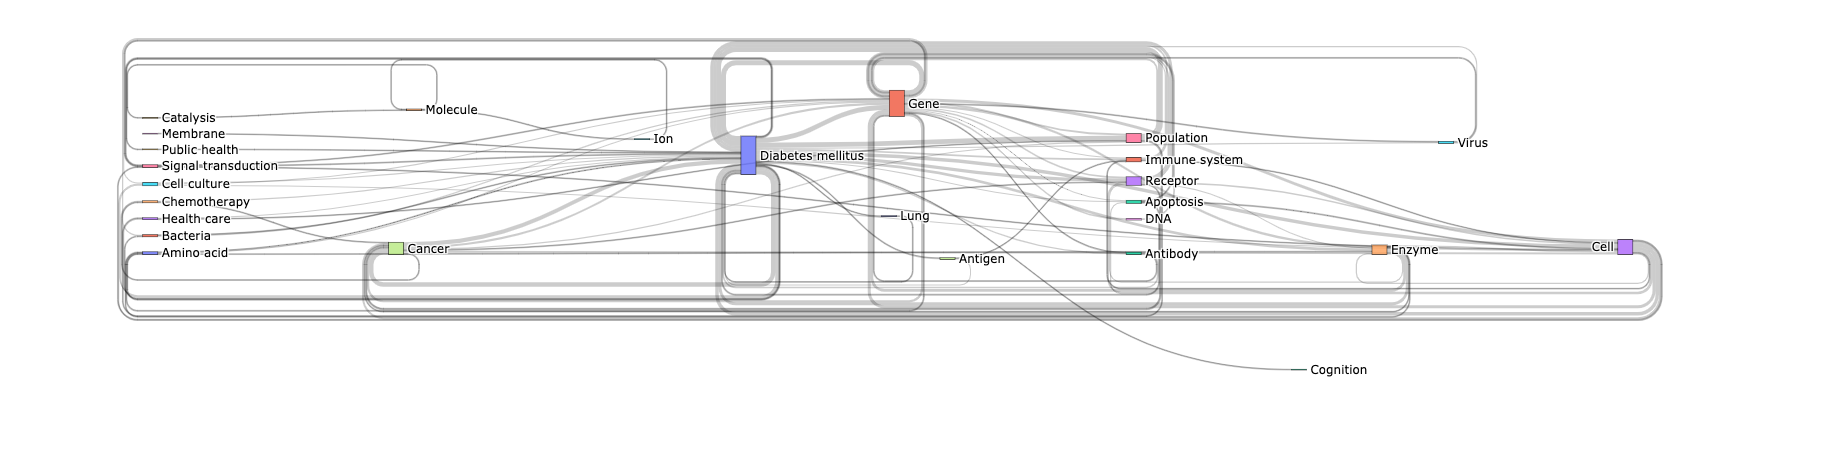

In [314]:
import plotly.graph_objects as go
import urllib, json

# url = 'https://raw.githubusercontent.com/plotly/plotly.js/master/test/image/mocks/sankey_energy.json'
# response = urllib.request.urlopen(url)
# data = json.loads(response.read())
fig = go.Figure(data=[go.Sankey(
#     valueformat = ".0f",
#     valuesuffix = "TWh",
    # Define nodes
    node = dict(
      pad = 15,
      thickness = 15,
      line = dict(color = "black", width = 0.5),
      label =  nodes),
    # Add links
    link = dict(
      source =  small_fos_graph['source'],
      target =  small_fos_graph['target'],
      value =  small_fos_graph['Weight']  ))])

# fig.update_layout(title_text="Energy forecast for 2050<br>Source: Department of Energy & Climate Change, Tom Counsell via <a href='https://bost.ocks.org/mike/sankey/'>Mike Bostock</a>",
#                   font_size=10)
fig.show()

In [304]:
data['data'][0]['node']['label']

["Agricultural 'waste'",
 'Bio-conversion',
 'Liquid',
 'Losses',
 'Solid',
 'Gas',
 'Biofuel imports',
 'Biomass imports',
 'Coal imports',
 'Coal',
 'Coal reserves',
 'District heating',
 'Industry',
 'Heating and cooling - commercial',
 'Heating and cooling - homes',
 'Electricity grid',
 'Over generation / exports',
 'H2 conversion',
 'Road transport',
 'Agriculture',
 'Rail transport',
 'Lighting & appliances - commercial',
 'Lighting & appliances - homes',
 'Gas imports',
 'Ngas',
 'Gas reserves',
 'Thermal generation',
 'Geothermal',
 'H2',
 'Hydro',
 'International shipping',
 'Domestic aviation',
 'International aviation',
 'National navigation',
 'Marine algae',
 'Nuclear',
 'Oil imports',
 'Oil',
 'Oil reserves',
 'Other waste',
 'Pumped heat',
 'Solar PV',
 'Solar Thermal',
 'Solar',
 'Tidal',
 'UK land based bioenergy',
 'Wave',
 'Wind']

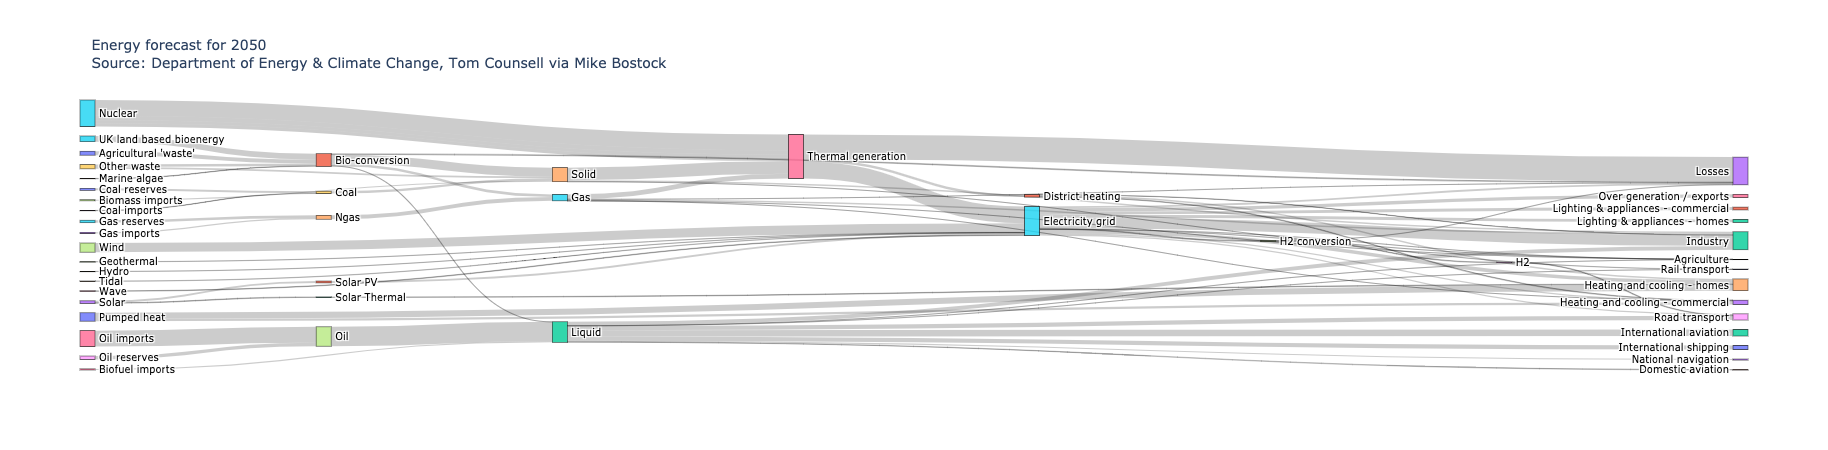

In [302]:
import plotly.graph_objects as go
import urllib, json

url = 'https://raw.githubusercontent.com/plotly/plotly.js/master/test/image/mocks/sankey_energy.json'
response = urllib.request.urlopen(url)
data = json.loads(response.read())
fig = go.Figure(data=[go.Sankey(
    valueformat = ".0f",
    valuesuffix = "TWh",
    # Define nodes
    node = dict(
      pad = 15,
      thickness = 15,
      line = dict(color = "black", width = 0.5),
      label =  data['data'][0]['node']['label']    ),
    # Add links
    link = dict(
      source =  data['data'][0]['link']['source'],
      target =  data['data'][0]['link']['target'],
      value =  data['data'][0]['link']['value']  ))])

fig.update_layout(title_text="Energy forecast for 2050<br>Source: Department of Energy & Climate Change, Tom Counsell via <a href='https://bost.ocks.org/mike/sankey/'>Mike Bostock</a>",
                  font_size=10)
fig.show()

In [447]:
papers_filtered = papers 

PaperId,Rank,Doi,DocType,PaperTitle,OriginalTitle
1968760089,21999,10.1002/(SICI)1096-9071(199812)56:4<294::AID- ...,Journal,analysis of the hepatitisb virus precore and o ...,Analysis of the HepatitisB Virus Precore and O ...
1968760983,23180,10.1016/S0769-2617(85)80041-1 ...,Journal,immune response tohepatitis b vaccination ...,Immune response tohepatitis B vaccination ...
2067957270,20481,10.1186/1471-2458-9-483,Journal,early detection ofinfluenza outbreaks u ...,Early detection ofinfluenza outbreaks u ...
1968761860,21099,10.1111/j.1478-3231.2008.01859.x ...,Journal,hepatic steatosis inpatients with chronic ...,Hepatic steatosis inpatients with chronic ...
2140104897,20588,10.1128/JVI.01040-13,Journal,hiv 1 gag cytotoxic tlymphocyte epitopes vary ...,HIV-1 gag cytotoxic Tlymphocyte epitopes vary ...
1968763470,20345,10.1371/journal.ppat.1000055 ...,Journal,control of viremia andprevention of aids ...,Control of Viremia andPrevention of AIDS ...
2140108426,20969,10.1128/CVI.00186-13,Journal,development of a highlysensitive bioluminescent ...,Development of a HighlySensitive Bioluminescent ...
140527580,20962,10.1023/A:1011399426632,Journal,through an ethnographiclens ethnographic met ...,Through an EthnographicLens: Ethnographic ...
140527580,20962,10.1023/A:1011399426632,Journal,through an ethnographiclens ethnographic met ...,Through an EthnographicLens: Ethnographic ...
2140108863,22212,10.1016/j.jhep.2007.09.002 ...,Journal,the anti hiv antiviralactivity of entecavir ...,The anti-HIV antiviralactivity of entecavir: ...


In [448]:
disease_authors = dict(zip(spothlight, [set()]*9))
res = {"Year":[],"Disease":[],"Value":[],"Type":[]}
for year in tqdm(range(2002,2019)):
    for d in spothlight:
        author_list = diseases_mag[(diseases_mag["Disease"]==d)&(diseases_mag["Year"]==year)&(diseases_mag["Authors List Sorted"]!=None)]["Authors List Sorted"]
        author_list = set(chain(*author_list))
        res["Year"].append(year)
        res["Disease"].append(d)
        res["Type"].append("New Authors")
        res["Value"].append(len(author_list-disease_authors[d]))
        res["Year"].append(year)
        res["Disease"].append(d)
        res["Type"].append("Distinct Authors")
        res["Value"].append(len(author_list))
        disease_authors[d] = disease_authors[d]|author_list

In [449]:
new_authors = pd.DataFrame(res)

In [450]:
new_authors = new_authors.sort_values(["Disease", "Year"])

In [451]:
import pycountry
import  functools
# @functools.lru_cache(maxsize=8048)
def get_iso(txt):
    try:
        return pycountry.countries.search_fuzzy(txt)[0].alpha_3
    except:
        pass
    return ""


In [467]:
diseases_mag_pairs_sars = diseases_mag_pairs

In [468]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars.groupby(["con_pairs", "Disease"],{ "Count":agg.SUM("Count")})

In [469]:
diseases_mag_pairs_sars["con_pairs"] = diseases_mag_pairs_sars["con_pairs"].apply(lambda x: [get_iso(l) for l in x])

In [470]:
iso_cord = defaultdict(str,zip(world["ISO3"],zip(world["LAT"],world["LON"])))

In [471]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars[diseases_mag_pairs_sars["con_pairs"].apply(lambda x: "" not in x)]

In [472]:
diseases_mag_pairs_sars["con_pairs"] = diseases_mag_pairs_sars["con_pairs"].apply(lambda x: [iso_cord[l] for l in x])

In [473]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars[diseases_mag_pairs_sars["con_pairs"].apply(lambda x: "" not in x)]

In [459]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars.unpack("con_pairs")

In [460]:
diseases_mag_pairs_sars = diseases_mag_pairs_sars.unpack("con_pairs.0").unpack("con_pairs.1")

In [474]:
df = diseases_mag_pairs_sars.to_dataframe()

In [537]:
sf = df.groupby("Disease").apply(lambda x: x.nlargest(10, 'Count')).reset_index(drop=True)  

In [538]:
sf =SFrame(sf)

In [495]:
current_palette = sns.color_palette().as_hex()


In [497]:
colordict={}
cmap = plt.cm.flag
colors = cmap(np.linspace(0., 1., len(countries)))
for l,c in zip(spothlight,current_palette):
    colordict[l]=c

In [517]:
import folium

for d in spothlight:
    m = folium.Map(location=[36.5,-122], zoom_start=3, tiles='Stamen Terrain', crs="EPSG3857")
    # Create the map with the appoximate location of San Andreas Fault
    for line in sf[sf["Disease"]==d]:
        max_count = sf[sf["Disease"]==d]["Count"].max()
        SAF = folium.PolyLine(locations= line["con_pairs"],weight=5*line["Count"]/max_count,color = colordict[line["Disease"]], tooltip=line["Disease"])
        m.add_child(SAF)
    m.save(f"output/Collab/Maps/{d.replace('/','-')}-collab2.html")

In [518]:
legend_html = ['''
            <div style="position: fixed; 
            bottom: 100px; left: 50px; width: 200px; height: 290px; 
            border:2px solid grey; z-index:9999; font-size:14px;
            background-color:white;
            ">&nbsp; Diseases <br>
            ''']
for k, v in colordict.items():
    legend_html.append(f'''
            &nbsp; {k} &nbsp; <i class="fa fa-map-marker fa-2x"
                      style="color:{v}"></i><br>
            ''')
legend_html.append("</div>")
m.get_root().html.add_child(folium.Element(" ".join(legend_html)))
m

In [315]:
m.save("map.html")

In [519]:
sf = get_research_cop(diseases_mag,"Dict of AuthorId_Country", n=1).groupby(["Disease","con_pairs"],agg.COUNT).sort("Count",False)

In [520]:
country_cord = defaultdict(str,zip(world["NAME"],zip(world["LAT"],world["LON"])))

In [521]:
iso_cord[""]=(0,0)

In [522]:
sf= sf.to_dataframe()

In [523]:
sf["Country"] = sf["con_pairs"].apply(lambda x: iso_cord[get_iso(x[0])])

In [524]:
sf = sf[["Disease","Count","Country"]]

In [525]:
sf = sf[sf["Country"]!=(0,0)]

In [527]:
sf = sf[sf["Country"]!=""]

In [528]:
sf2 = SFrame(sf)

In [536]:
import folium

for d in spothlight:
    m = folium.Map(location=[36.5,-122], zoom_start=3, tiles='Stamen Terrain', crs="EPSG3857")
    # Create the map with the appoximate location of San Andreas Fault
    for line in sf[sf["Disease"]==d]:
        max_count = sf[sf["Disease"]==d]["Count"].max()
        SAF=folium.PolyLine(locations=line["con_pairs"],weight=5*line["Count"]/max_count,color = colordict[line["Disease"]], tooltip=line["Disease"])
        m.add_child(SAF)
    m.save(f"output/Collab/Maps/{d.replace('/','-')}-collab.html")

TypeError: Location should be a sized variable, for example a list or a tuple, instead got 33.42 of type <class 'float'>.

In [547]:
for d in spothlight:
    m = folium.Map(location=[36.5,-122], zoom_start=3, tiles='Stamen Terrain', crs="EPSG3857")
    # Create the map with the appoximate location of San Andreas Fault
    for line in sf2[sf2["Disease"]==d]:
        max_count = sf2[sf2["Disease"]==d]["Count"].max()
        folium.Circle(
          location=list(line["Country"]),
          popup=line['Count'],
          radius=(line['Count']/max_count)*1000000,
          color=colordict[line["Disease"]],
          fill=True,
          fill_color='crimson'
       ).add_to(m)
    for line in sf[sf["Disease"]==d]:
        max_count = sf[sf["Disease"]==d]["Count"].max()
        SAF=folium.PolyLine(locations=line["con_pairs"],weight=5*line["Count"]/max_count,color = colordict[line["Disease"]], tooltip=line["Disease"])
        m.add_child(SAF)
    m.save(f"output/Collab/Maps/{d.replace('/','-')}2.html")

In [89]:
# These examples are inspired from http://geopandas.org/mapping.html
import geopandas
import matplotlib.pyplot as plt
%matplotlib inline

world = geopandas.read_file("http://thematicmapping.org/downloads/TM_WORLD_BORDERS_SIMPL-0.3.zip")


In [183]:
world["iso_a3"] = world.apply(lambda x: get_iso(x["name"]) if x["iso_a3"] == "-99" else x["iso_a3"], axis=1)

In [170]:
world["cord"] = world["geometry"].centroid


In [ ]:
from geonamescache.mappers import country
mapper = country(from_key='name', to_key='name')

In [497]:
import networkx as nx

'2.2'

In [548]:
g = nx.Graph()

In [549]:
pairs = diseases_mag_pairs.groupby(["con_pairs", "Disease"],{ "Count":agg.SUM("Count")})

In [550]:
inter = get_research_cop(diseases_mag,"Dict of AuthorId_Country", n=1).groupby(["Disease","con_pairs"],agg.COUNT).sort("Count",False)

In [551]:
inter["Country"] = inter["con_pairs"].apply(lambda x: x[0])

In [552]:
graphs = dict(zip(spothlight,[nx.Graph() for x in spothlight]))
for d in tqdm(spothlight):
    total_papers = inter[inter["Disease"]==d]["Count"].sum()
    for line in inter[inter["Disease"]==d]:
        if line['Count']/total_papers>0.05:
            
            graphs[d].add_node(line["Country"], weight=line['Count'])
    nodes = set(graphs[d].nodes)
    for line in pairs[pairs["Disease"]==d]:
        if line["con_pairs"][0] in nodes and line["con_pairs"][1] in  nodes:
            graphs[d].add_edge(*line["con_pairs"], weight=line['Count'])
    nx.write_gml(  graphs[d], f"output/Collab/Cyto/{d.replace('/','-')}.gml")
    with open(f"output/Collab/Cyto/{d.replace('/','-')}.json", "w") as f :
        f.write(json.dumps(nx.cytoscape_data(graphs[d])))


In [553]:
import matplotlib.pyplot as plt

In [554]:
import json

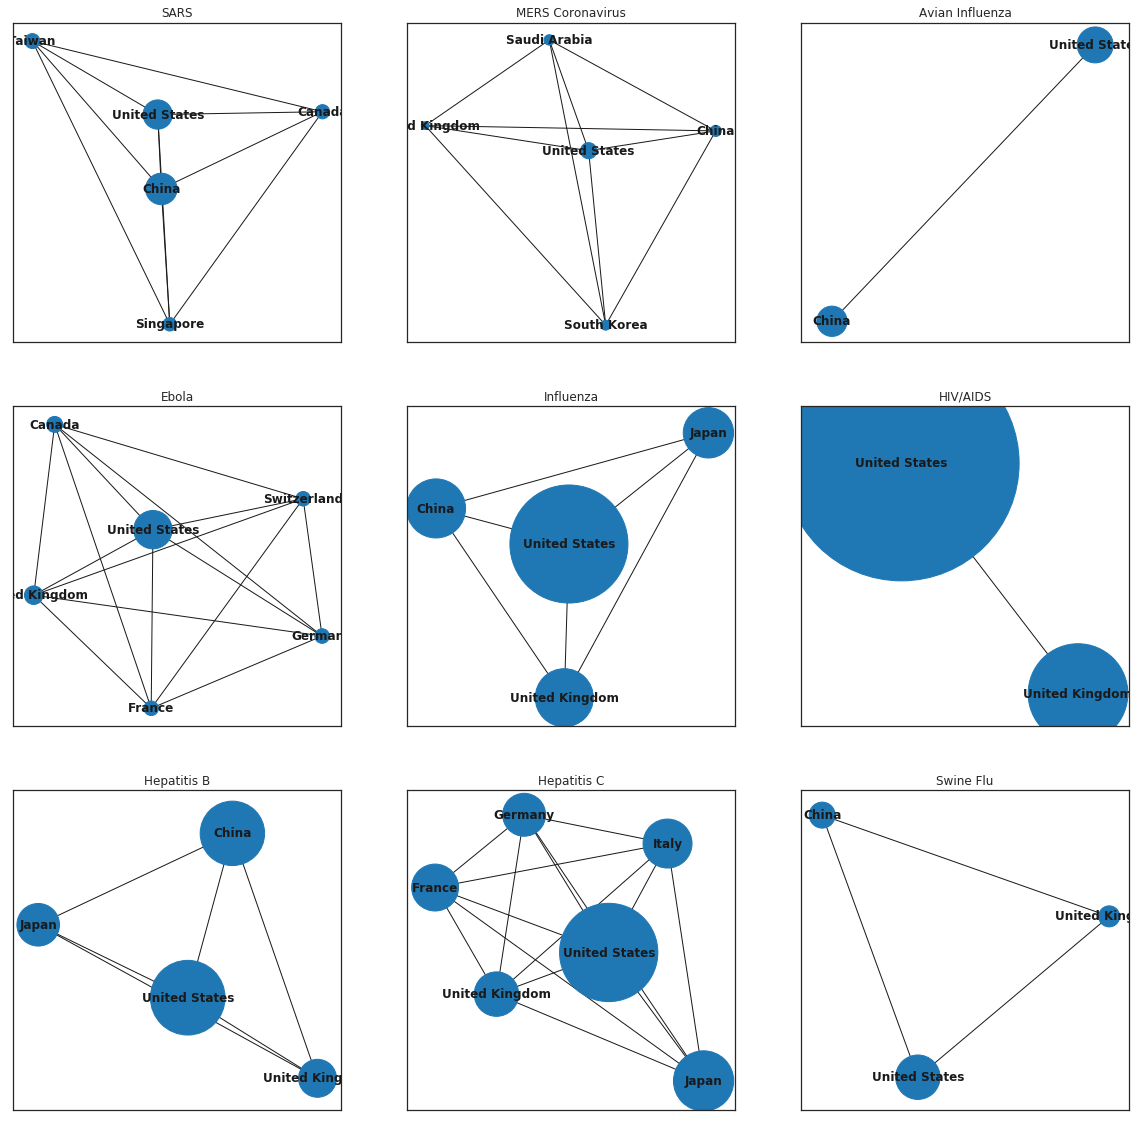

In [556]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for g,ax in tqdm(zip(graphs.items(),axes)):
    ax.set_title(g[0])

    nx.draw_networkx(g[1], with_labels=True, font_weight='bold', ax=ax, node_size=[g[1].nodes[v]['weight'] for v in g[1].nodes])
    plt.title(g[0])


#     df.unstack().plot.bar(ax=ax, stacked=True)


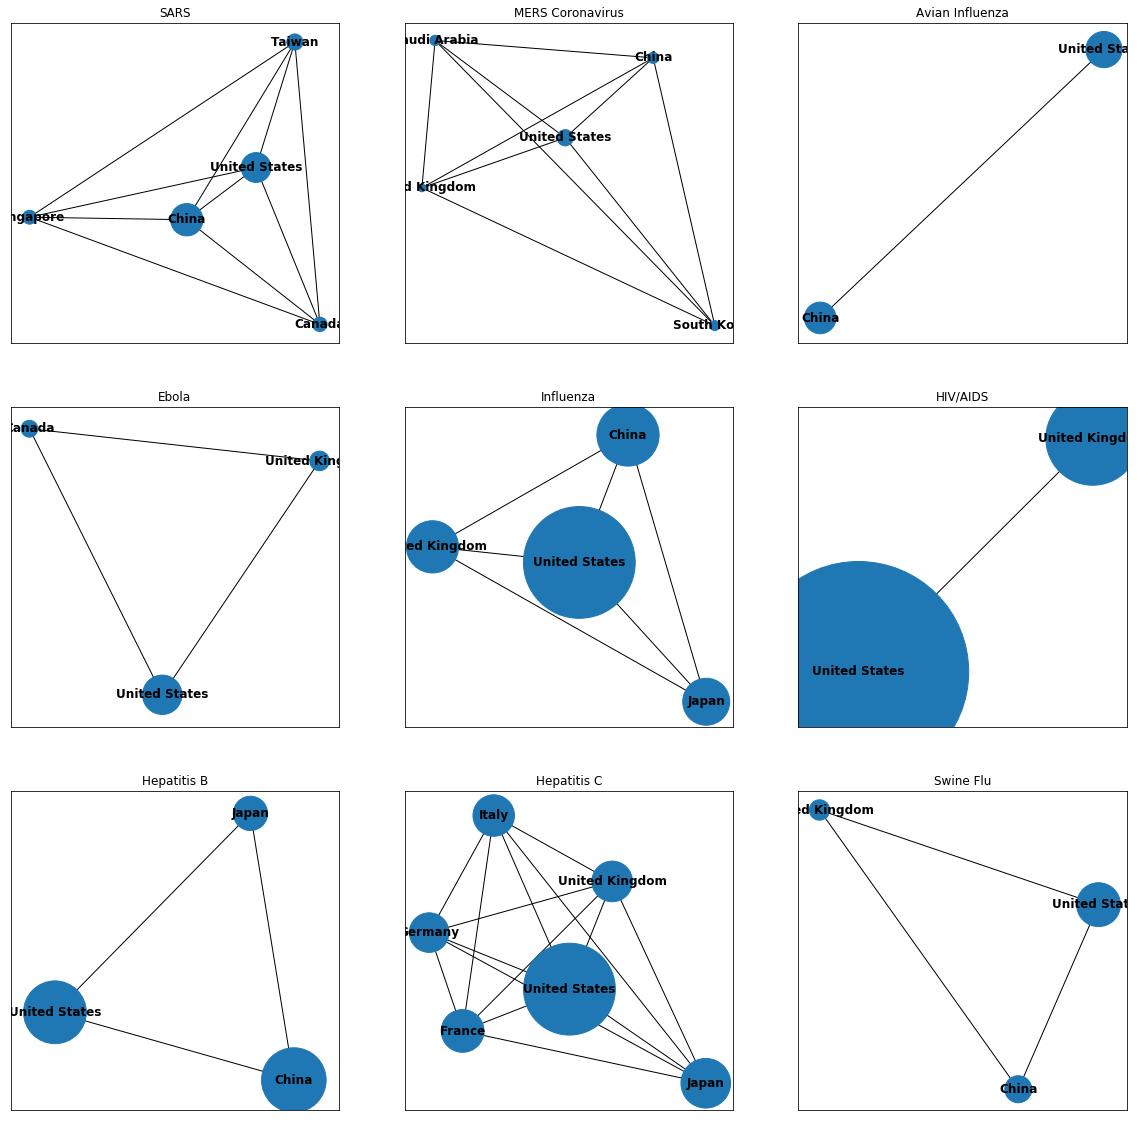

In [104]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for g,ax in tqdm(zip(graphs.items(),axes)):
    ax.set_title(g[0])

    nx.draw_networkx(g[1], with_labels=True, font_weight='bold', ax=ax, node_size=[g[1].nodes[v]['weight'] for v in g[1].nodes])
    plt.title(g[0])


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [558]:
inter = inter.join(inter.groupby("Disease",{ "Total":agg.SUM("Count")}))

In [559]:
inter["p%"] = inter["Count"]/ inter["Total"]

In [560]:
inter = inter.sort(["Disease","p%"],False)

In [561]:
spothlight = sorted(spothlight,reverse=True)

In [563]:
res = []
for d in spothlight:
    res+=list(inter[inter["Disease"]==d]["p%"].cumulative_sum())

In [564]:
inter["cumulative_sum"]=res

In [565]:
inter["Pie_Country"] = inter.apply(lambda x: "Others" if x["p%"]<0.02 else x["Country"])

In [566]:
inter2 = inter.groupby(["Disease","Pie_Country"],{"Count":agg.SUM("Count")})

In [567]:
countries = list(inter2["Pie_Country"].unique())

In [568]:
len(countries)

22

In [572]:
inter2 = inter2.sort(["Disease","Count"],False)

In [646]:
from matplotlib.colors import ListedColormap

def generate_colormap(N):
    arr = np.arange(N)/N
    N_up = int(math.ceil(N/7)*7)
    arr.resize(N_up)
    arr = arr.reshape(7,N_up//7).T.reshape(-1)
    ret = cm.GnBu_r(arr)
    n = ret[:,3].size
    a = n//2
    b = n-a
    for i in range(3):
        ret[0:n//2,i] *= np.arange(0.2,1,0.8/a)
    ret[n//2:,3] *= np.arange(1,0.1,-0.9/b)
#     print(ret)
    return ret

In [647]:
colordict={}

for l,c in zip(countries,generate_colormap(len(countries))):
    colordict[l]=c

# fig = plt.figure(figsize=[10, 10])
# ax = fig.add_subplot(111)

# pie_wedge_collection = ax.pie(slices, labels=labels, labeldistance=1.05)#, autopct=make_autopct(slices))

# for pie_wedge in pie_wedge_collection[0]:
#     pie_wedge.set_edgecolor('white')
#     pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])

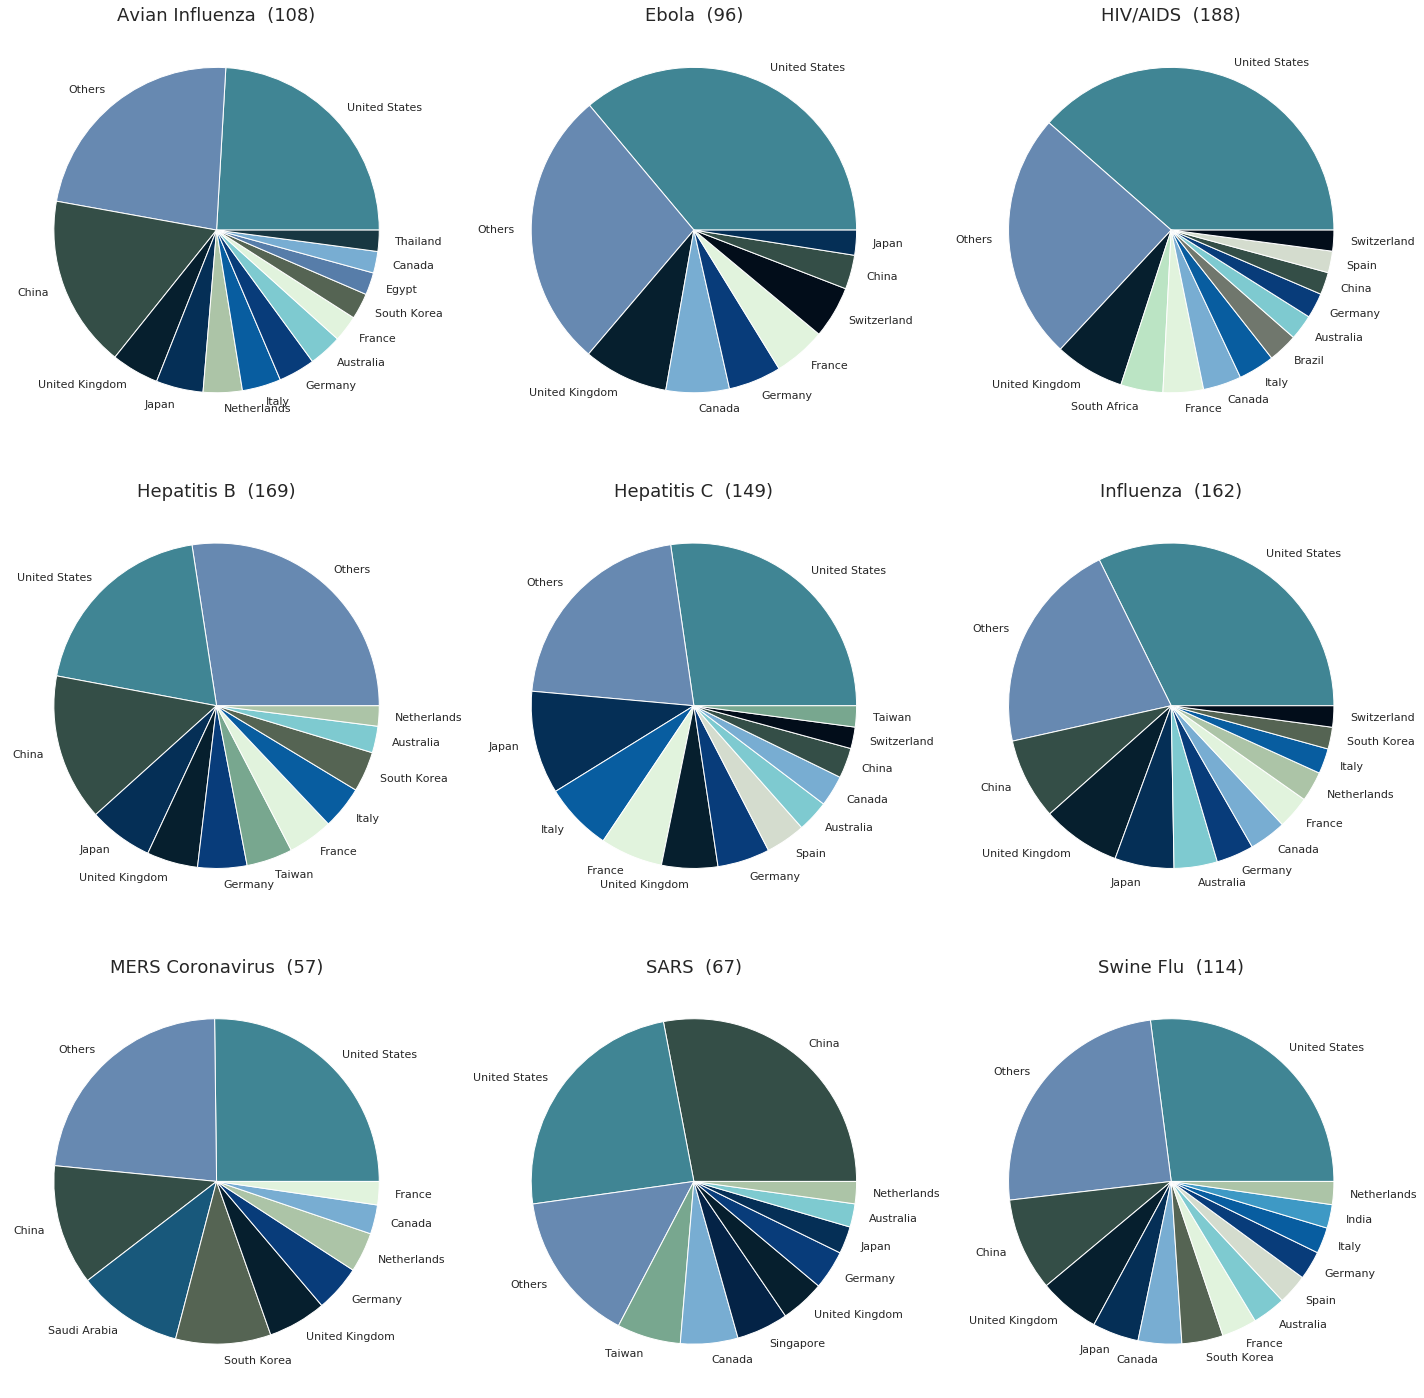

In [649]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for d,ax in tqdm(zip(sorted(spothlight),axes)):

    ax.set_title(f'{d}  ({len(set(inter[inter["Disease"]==d]["Country"]))})', fontsize=18)
    data = inter2[inter2["Disease"]==d]
    pie_wedge_collection = ax.pie(data["Count"],  labels=data["Pie_Country"])
    
    for pie_wedge in pie_wedge_collection[0]:
        pie_wedge.set_edgecolor('white')
        pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])
fig.tight_layout()


#     df.unstack().plot.bar(ax=ax, stacked=True)


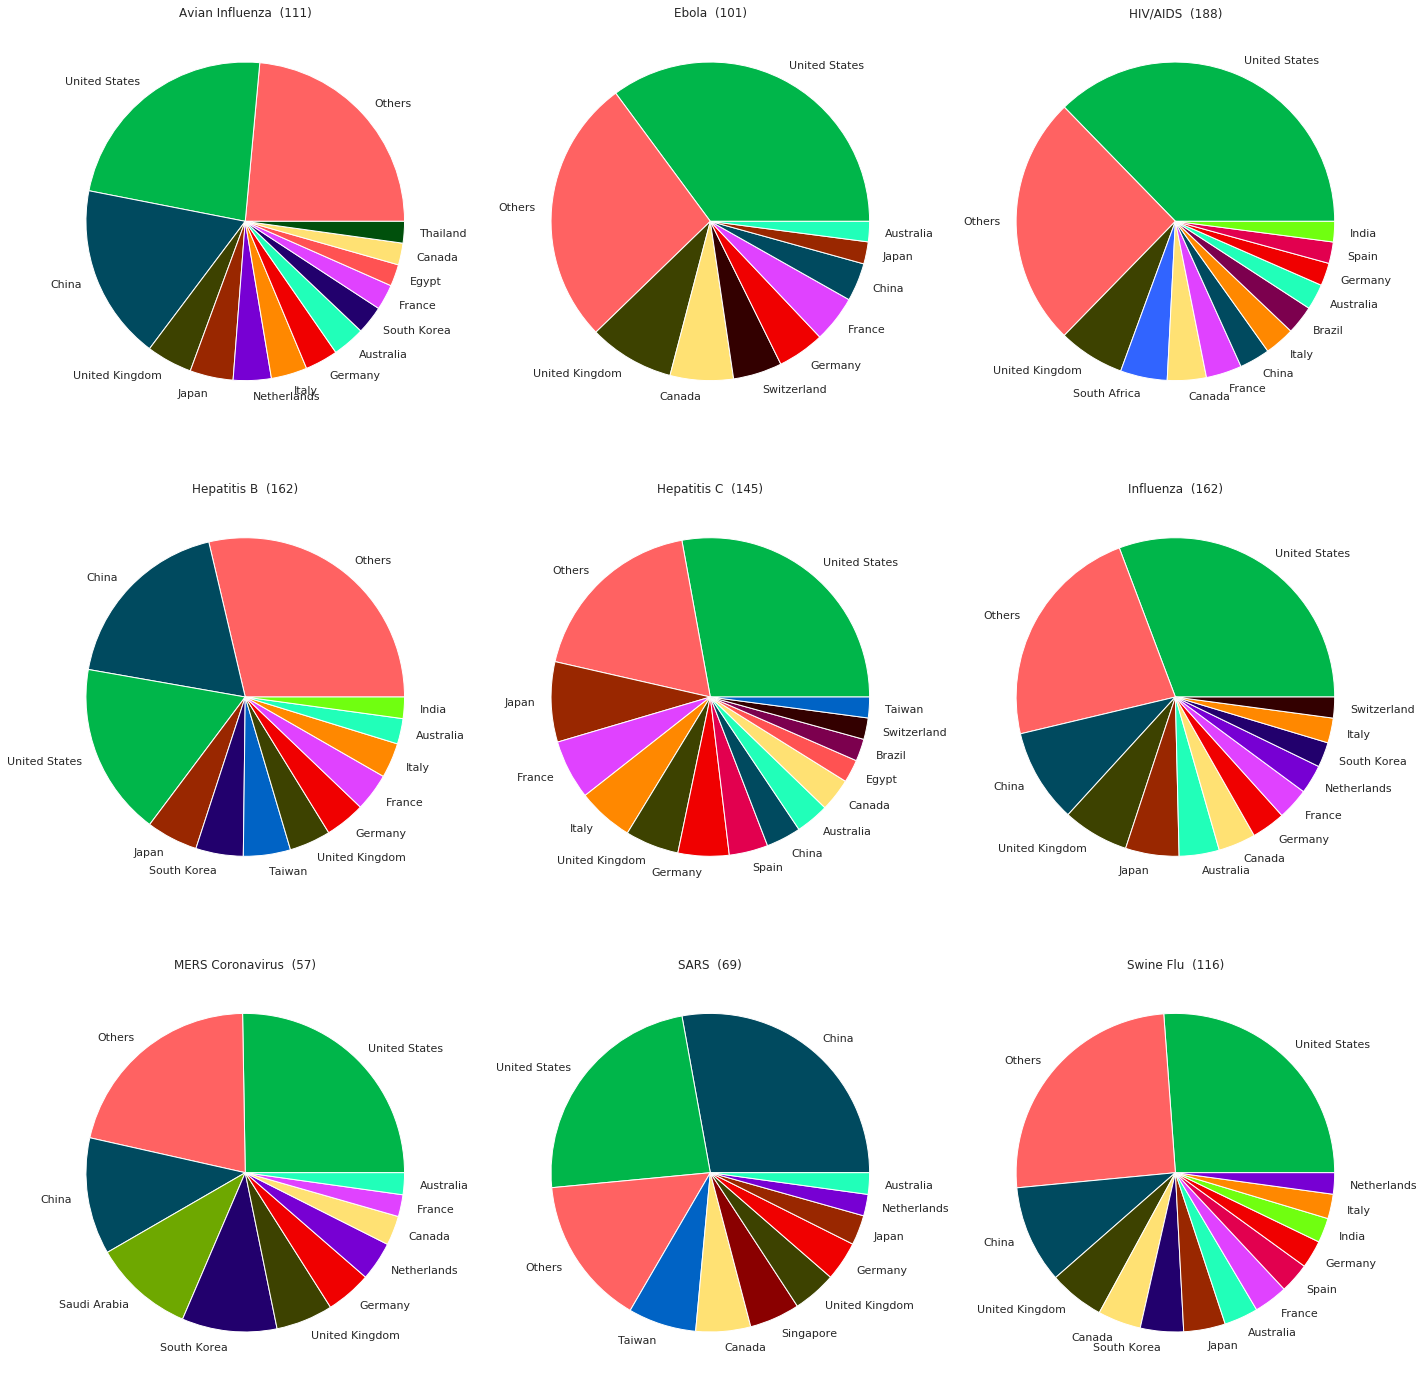

In [350]:
fig, axes = plt.subplots(3,3,figsize=(20,20))
axes = axes.flatten()

for d,ax in tqdm(zip(sorted(spothlight),axes)):

    ax.set_title(f'{d}  ({len(set(inter[inter["Disease"]==d]["Country"]))})')
    data = inter2[inter2["Disease"]==d]
    pie_wedge_collection = ax.pie(data["Count"],  labels=data["Pie_Country"])
    
    for pie_wedge in pie_wedge_collection[0]:
        pie_wedge.set_edgecolor('white')
        pie_wedge.set_facecolor(colordict[pie_wedge.get_label()])
fig.tight_layout()


#     df.unstack().plot.bar(ax=ax, stacked=True)


In [609]:
for d in spothlight:
    print(inter[inter["Disease"]==d][:6][["Disease","Country","cumulative_sum"]])

+-----------+----------------+---------------------+
|  Disease  |    Country     |    cumulative_sum   |
+-----------+----------------+---------------------+
| Swine Flu | United States  |  0.2704626334519573 |
| Swine Flu |     China      | 0.36285245004106215 |
| Swine Flu | United Kingdom | 0.42335067068163157 |
| Swine Flu |     Japan      |  0.4693402682726526 |
| Swine Flu |     Canada     |  0.5125923898165892 |
| Swine Flu |  South Korea   |  0.553654530522858  |
+-----------+----------------+---------------------+
[6 rows x 3 columns]

+---------+----------------+--------------------+
| Disease |    Country     |   cumulative_sum   |
+---------+----------------+--------------------+
|   SARS  |     China      | 0.280022605255722  |
|   SARS  | United States  | 0.5221814071771687 |
|   SARS  |     Taiwan     | 0.5854761231986436 |
|   SARS  |     Canada     | 0.6425543938965809 |
|   SARS  |   Singapore    | 0.6939813506640293 |
|   SARS  | United Kingdom | 0.7377790336253178 

In [610]:
world2 = geopandas.read_file(geopandas.datasets.get_path('naturalearth_lowres'))

In [611]:
world2= world2.replace("United States of America", "United States")

In [612]:
inter = inter.join(SFrame(world2[["name","continent"]]), on={"Country":"name"},how='left')

In [613]:
continent = inter.groupby(["Disease","continent"],{"Count":agg.SUM("Count"), "p%":agg.SUM("p%")})

In [614]:
continent.sort(["Disease","p%"]).print_rows(63)

+------------------+---------------+-------+-----------------------+
|     Disease      |   continent   | Count |           p%          |
+------------------+---------------+-------+-----------------------+
| Avian Influenza  | South America |   35  |  0.006521334078628656 |
| Avian Influenza  |      None     |   56  |  0.010434134525805851 |
| Avian Influenza  |    Oceania    |  200  |  0.037264766163592325 |
| Avian Influenza  |     Africa    |  250  |  0.046580957704490396 |
| Avian Influenza  |     Europe    |  1408 |  0.26234395379168995  |
| Avian Influenza  | North America |  1439 |   0.2681199925470467  |
| Avian Influenza  |      Asia     |  1979 |  0.36873486118874604  |
|      Ebola       | South America |   19  |  0.004664866191996071 |
|      Ebola       |      None     |   45  |  0.011048367296832801 |
|      Ebola       |    Oceania    |   81  |  0.019887061134299045 |
|      Ebola       |      Asia     |  397  |  0.09747115148539162  |
|      Ebola       |     Africa   

In [615]:
inter[inter["Disease"]=="MERS Coronavirus"]

Disease,con_pairs,Count,Country,Total,p%,cumulative_sum
MERS Coronavirus,[United States],261,United States,1036,0.2519305019305019,0.2519305019305019
MERS Coronavirus,[China],124,China,1036,0.11969111969111969,0.3716216216216216
MERS Coronavirus,[Saudi Arabia],109,Saudi Arabia,1036,0.10521235521235521,0.4768339768339768
MERS Coronavirus,[South Korea],98,South Korea,1036,0.0945945945945946,0.5714285714285714
MERS Coronavirus,[United Kingdom],60,United Kingdom,1036,0.05791505791505792,0.6293436293436293
MERS Coronavirus,[Germany],48,Germany,1036,0.04633204633204633,0.6756756756756757
MERS Coronavirus,[Netherlands],41,Netherlands,1036,0.03957528957528957,0.7152509652509652
MERS Coronavirus,[Canada],30,Canada,1036,0.02895752895752896,0.7442084942084942
MERS Coronavirus,[France],24,France,1036,0.023166023166023165,0.7673745173745173
MERS Coronavirus,[Australia],20,Australia,1036,0.019305019305019305,0.7866795366795366


In [616]:
first_author =  diseases_mag.groupby(["Disease","first_atuhor_country"], agg.COUNT())

In [617]:
first_author = first_author[first_author["first_atuhor_country"]!=""]

In [620]:
# first_author = first_author.remove_column("Total")

In [621]:
first_author = first_author.join(first_author.groupby("Disease",{ "Total":agg.SUM("Count")}))

In [622]:
first_author["p%"] = first_author["Count"]/ first_author["Total"]

In [623]:
first_author = first_author.sort(["Disease","p%"],False)

In [625]:
spothlight = sorted(spothlight,reverse=True)

In [626]:
res = []
for d in spothlight:
    res+=list(first_author[first_author["Disease"]==d]["p%"].cumulative_sum())

In [627]:
first_author["cumulative_sum"]=res

In [628]:
for d in spothlight:
    print(first_author[first_author["Disease"]==d][:6][["Disease","first_atuhor_country","cumulative_sum"]])

+-----------+----------------------+---------------------+
|  Disease  | first_atuhor_country |    cumulative_sum   |
+-----------+----------------------+---------------------+
| Swine Flu |    United States     |  0.2733293196869356 |
| Swine Flu |        China         | 0.38390527794501306 |
| Swine Flu |    United Kingdom    |  0.4368854103953442 |
| Swine Flu |        Canada        | 0.48705599036724867 |
| Swine Flu |        Japan         |  0.5364238410596027 |
| Swine Flu |     South Korea      |  0.5851896447922939 |
+-----------+----------------------+---------------------+
[6 rows x 3 columns]

+---------+----------------------+---------------------+
| Disease | first_atuhor_country |    cumulative_sum   |
+---------+----------------------+---------------------+
|   SARS  |        China         | 0.32389162561576357 |
|   SARS  |    United States     |  0.5529556650246306 |
|   SARS  |        Taiwan        |  0.6264367816091954 |
|   SARS  |        Canada        |  0.68678160

In [629]:
first_author = first_author.join(SFrame(world2[["name","continent"]]), on={"first_atuhor_country":"name"},how='left')

In [630]:
first_author_continent = first_author.groupby(["Disease","continent"],{"Count":agg.SUM("Count"), "p%":agg.SUM("p%")})

In [631]:
first_author_continent[first_author_continent["continent"]!=None].sort(["Disease","p%"]).print_rows(63)

+------------------+---------------+-------+-----------------------+
|     Disease      |   continent   | Count |           p%          |
+------------------+---------------+-------+-----------------------+
| Avian Influenza  | South America |   22  |  0.006457293806868213 |
| Avian Influenza  |     Africa    |  113  |  0.03316700909891399  |
| Avian Influenza  |    Oceania    |  117  |  0.03434106251834458  |
| Avian Influenza  |     Europe    |  768  |  0.22541825653067218  |
| Avian Influenza  | North America |  933  |  0.27384796008218376  |
| Avian Influenza  |      Asia     |  1430 |  0.41972409744643396  |
|      Ebola       | South America |   13  |  0.005684302579798864 |
|      Ebola       |    Oceania    |   39  |  0.017052907739396588 |
|      Ebola       |     Africa    |  122  |  0.05334499344118934  |
|      Ebola       |      Asia     |  237  |  0.10362920857017928  |
|      Ebola       |     Europe    |  663  |   0.289899431569742   |
|      Ebola       | North America

## Geolocation

In [ ]:
diseases_mag = load_sframe("Data/mag/diseases_mag.sframe")

In [7]:
def get_geolocation_map(geolocator, geolcoator_name):
    """
    Create a locations' data dict for each location that appear in SFrame locations column
    :param geolocator: geopy geolocator object
    :param geolcoator_name: the geolocator name
    :return: dict which each location data collected using the input gelocator
    :rtype: dict
    :note: Example for createing a geolocator
    from geopy import Bing
    b = Bing(BING_MAPS_API_KEY)
    self._create_locations_data_dict(b, "Bing")
    """
    d = {}

    loc_dict = Counter(locations)
    
    for loc, v in tqdm(loc_dict.most_common()):
        if loc in d:
            continue
            
        try:
            gcode = geolocator.geocode(loc)
            if gcode is not None:
                gcode = gcode.raw

            d[geolcoator_name][loc] = gcode
            time.sleep(1.2)  # sleep 1200 milisecs to not limit api limitations
        except GeocoderTimedOut:
            print("GeocoderTimedOut")
            time.sleep(5)
            pass
    return d

In [8]:
import functools

In [9]:
institution = SFrame.read_csv("Data/journals/ScimagoIR.csv",delimiter=";")
institution["Institution"] = institution["Institution"].apply(lambda x: x.replace(" *",""))
institutions = [l.lower() for l in institution["Institution"]]
institution_country = {l["Institution"].lower() : l["Country"] for l in institution}

@functools.lru_cache(maxsize=2048)
def match_inst(l):
    for i in institutions:
        if i in l.lower() or l.lower() in i:
            return i.title(), institution_country[i]
    return False


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/journals/ScimagoIR.csv

Parsing completed. Parsed 100 lines in 0.036701 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[int,str,str,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/journals/ScimagoIR.csv

Parsing completed. Parsed 6459 lines in 0.036736 secs.

In [159]:
from geopy.exc import GeocoderTimedOut , GeocoderNotFound, GeocoderServiceError
import time

In [ ]:
mapbox_map = {}
mapbox_map_i = {}
max_iso_iter = max_iso.iterrows()
for i, row in tqdm(max_iso_iter, total=len(max_iso)):
    loc= True
    try:
        if mapbox_map_i[i]:
            continue
    except:
        pass
    timeout = 1
    try:
        while 0<timeout<3:
            try:
                loc = mb.geocode(row["ORG Clean4"], country=row["iso"] )
                timeout = 0
            except  GeocoderTimedOut:
                timeout +=1
                time.sleep(5*timeout)
    except GeocoderServiceError:
        continue
    mapbox_map[row["ORG Clean4"]] = loc
    mapbox_map_i[i] = loc

In [10]:
from unidecode import unidecode
import spacy
from collections import defaultdict
from itertools import chain
res = []
nlp = spacy.load('en_core_web_lg', disable=['parser', 'tagger', 'textcat'])
    
def clean_orgs(o_list):
    black_list = ["Department", "Faculty" ,"Division" , "Centre", "Unit", "Laboratory", "Program", "Group", "Studies"]
    for b in black_list:
        o_list =  [ o for o in o_list if b not in o ]
    return o_list

def priorityze_keywords(uni):
    keywords =  ["University","Hospital", "Institut", "College", "School", "Medical Center"]
    for k in keywords:
        for u in uni:
            if k in u:
                return [u]
    return uni

def stndartize_affiliation(aff):
    inst = match_inst(aff)
    if inst:
        return inst
    doc = nlp(aff)
    orgs = [ent.text for ent in doc.ents if ent.label_ == "ORG"]
    orgs = list(chain.from_iterable([o.split(", ") for o in orgs ]))
    orgs = clean_orgs(orgs)
    if len(orgs) == 0:
        return False
    orgs =  orgs if len(orgs[-1])>2 else orgs[:-1]
    orgs = priorityze_keywords(orgs)
#     universities = universities[universities["ORG Clean"].str.len() != 0]
    if len(orgs) == 0:
        return False
    return orgs[-1]

def affiliations_to_location(aff):
    aff = stndartize_affiliation(aff)
    if not aff:
        return False
    try:
        if mapbox_map[aff] is not np.nan:
            return mapbox_map[aff]
    except KeyError:
        return False
    return False


In [235]:
diseases_pubmed["loc"] = diseases_pubmed["affiliations"].apply(lambda aff: [affiliations_to_location(x) for x in aff])

['Rockefeller University']


NameError: name 'mapbox_map' is not defined

In [11]:
from itertools import chain
# locations = list(chain.from_iterable(diseases_pubmed[diseases_pubmed["affiliations"]!=""]["affiliations"]))
locations_raw = list(chain.from_iterable(diseases_pubmed[diseases_pubmed["affiliations"]!=""]["affiliations"]))

locations_raw = set(locations_raw)
locations_raw = [l.strip() for l in locations_raw]

In [12]:
def match_inst(l):
    for i in institutions:
        if i in l.lower() or l.lower() in i:
            return l, i
    return False


In [13]:
import concurrent
max_workers = 12
institutions_map = {}
institutions_tuples = []
with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
    for res in tqdm(executor.map(match_inst, locations_raw), total=len(locations_raw)):
        if res:
            institutions_map[res[0]]=res[1]

In [14]:
from collections import defaultdict
institutions_d = defaultdict(str, institutions_map)

In [46]:
def get_entites(uni):
    d = defaultdict(list)
    temp_res = []
    for u in uni:
        doc = nlp(u)
        for ent in doc.ents:
            d[ent.label_].append(ent.text)
        temp_res.append(d)
    return temp_res
import concurrent
max_workers = 12
res = []
with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
    for entites in tqdm(executor.map(get_entites, diseases_pubmed["affiliations"]), total=len(diseases_pubmed["affiliations"])):
        res.append(entites)

In [15]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]
        

        
        
def get_entites(uni):
    d = defaultdict(list)
    doc = nlp(uni)
    for ent in doc.ents:
        d[ent.label_].append(ent.text)
    return uni , d

import concurrent
max_workers = 12
res = []
# with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
#     for e in tqdm(executor.map(get_entites, locations_raw), total=len(locations_raw)):
#         res.append(e)

                
batch_size = 10000

for batch in tqdm(chunks(locations_raw, batch_size), total=len(locations_raw)//batch_size):
    with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
        for e in executor.map(get_entites, batch):
            res.append(e)


In [16]:
from pandas.io.json import json_normalize

df2 = json_normalize( pd.DataFrame(res)[1])

In [54]:
universities=df2[["ORG","GPE"]]

In [55]:
universities["raw"] = pd.DataFrame(res)[0]

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [56]:
len(universities)

745685

In [57]:
universities["uni"] = universities["raw"].apply(lambda x: institutions_d[x])

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [60]:
universities = universities.iloc[1:]

In [74]:
for row in universities.loc[universities.ORG.isnull(), 'ORG'].index:
    universities.at[row, 'ORG'] = []
for row in universities.loc[universities.GPE.isnull(), 'GPE'].index:
    universities.at[row, 'GPE'] = []

In [72]:
def match_inst(insts):
    for i in institutions:
        for l in insts:
            if i in l.lower() or l.lower() in i:
                return l, i
    return ("",)

In [ ]:
universities["uni"] = universities.progress_apply(lambda x: x["uni"] if x["uni"] else match_inst(x["ORG"])[0].lower(), axis=1)

In [58]:
institution_country = defaultdict(str, institution_country)

In [ ]:
universities["uni"] = universities["uni"].progress_apply(lambda x: x if x else "")

In [41]:
universities["country"] = universities["uni"].apply(lambda x: institution_country[x.lower()])

In [119]:
universities.to_csv("Data/universities.csv")

In [50]:
# universities["country"] = universities["country"].progress_apply(lambda x: x if x else "")

In [86]:
import pycountry
import  functools
# @functools.lru_cache(maxsize=8048)
def get_iso(txt):
    try:
        return pycountry.countries.search_fuzzy(txt)[0].alpha_2
    except:
        pass
    return ""


In [86]:
universities["country"] = universities["country"].progress_apply(lambda x: alpha_3_to_2(x))

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [ ]:
universities["iso"] = universities["GPE"].progress_apply(lambda locs: [ get_iso(x) for x in locs])

In [93]:
[][-1]

IndexError: list index out of range

In [102]:
 [i for i in ["",1,2,3,""] if i]

[1, 2, 3]

In [103]:
universities["iso"] = universities["iso"].progress_apply(lambda x: [i for i in x if i])

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [104]:
universities["iso2"] = universities["iso"].progress_apply(lambda x: x[-1] if x else "")

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [107]:
universities.iloc[31]

ORG        [Department of Oral Medicine and Radiology Dr ...
GPE                                           [Bihar, India]
raw        Department of Oral Medicine and Radiology Dr B...
uni                                                         
country                                                     
iso                                                 [IN, IN]
iso2                                                      IN
Name: 32, dtype: object

In [108]:
universities["country_join"] = universities.progress_apply(lambda x: x["country"] if x["country"] else x["iso2"] , axis=1)

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [116]:
universities["country_join"] = universities.progress_apply(lambda x: "GB" if "GB" in  x["iso"]  else x["country_join"]  , axis=1)

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [128]:
uni_coutrtry = {line[1]["raw"]: line[1]["country_join"] for line in universities.iterrows()}

In [135]:
uni_coutrtry = defaultdict(str, uni_coutrtry)

In [169]:
universities["uni"] == ""

,ORG,GPE,raw,uni,country,iso,iso2,country_join
1,[Dongguan Eighth Peoples Hospital],"[Dongguan, China]","Dongguan Eighth Peoples Hospital, Dongguan, 52...",,,[CN],CN,CN
2,[DE],"[Suite 2E70, Newark, USA]",", 4755 OgletownStanton Road, Suite 2E70, Newar...",de,,[US],US,US
3,"[Centers for Disease Control and Prevention, M...","[Atlanta, USA]","Malaria Epidemiology Branch, Centers for Disea...",centers for disease control and prevention,US,[US],US,US
4,[Facultad de Ciencias Quimicas y Farmaceuticas...,[Chile],Departamento de Bioquimica y Biologia Molecula...,universidad de chile,CL,[CL],CL,CL
5,[Singapore General Hospital],[Singapore],"Singapore General Hospital, Singapore",singapore general hospital,SG,[SG],SG,SG
6,"[National Center for Communicable Diseases, Mi...","[Ulaanbaatar, Mongolia]","National Center for Communicable Diseases, Min...",ministry of health,MY,[MN],MN,MY
7,"[Institute for Food Safety and Hygiene, Vetsui...",[Zurich],"Institute for Food Safety and Hygiene, Vetsuis...",,,[CH],CH,CH
8,[University of Connecticut],[CT],"University of Connecticut, CT, USA",university of connecticut,,[ES],ES,ES
9,[Institut de Cancerologie],"[Villejuif, France]","Institut de Cancerologie Gustave Roussy, Ville...",,,[FR],FR,FR
10,"[Institute of Legal Medicine, University of Bo...",[Italy],"Institute of Legal Medicine, University of Bol...",,,[IT],IT,IT


In [171]:
uni_coutrtry["university of guelph".title()]

''

In [145]:
diseases_pubmed["aff_country"] = diseases_pubmed["affiliations"].apply(lambda affs: [uni_coutrtry[aff.strip()] for aff in affs])

In [151]:
diseases_pubmed["aff_country"] = diseases_pubmed["aff_country"].apply(lambda affs: [aff for aff in affs if aff])

In [152]:
x = diseases_pubmed[diseases_pubmed["aff_country"].apply(lambda x: len(x) >1 )]

In [154]:
diseases_pubmed["int_cloab"] = diseases_pubmed["aff_country"].apply(lambda affs: len(set(affs)))

In [158]:
diseases_pubmed.groupby("disease", operations={"int_cloab": agg.AVG("cint_cloab")})

disease,int_cloab
chlamydia,0.9822983984265208
varicella and herpeszoster ...,1.1489361702127663
meningitis,0.9621200189006128
trachoma,1.2494669509594876
meningococcemia,0.8749999999999996
gonococcal,0.9259615384615375
triple e,1.0
sleeping sickness,1.1322314049586768
hookworm disease,0.6896551724137929
leprosy,0.9280672268907549


In [34]:
from tqdm import tqdm


In [35]:
tqdm.pandas()

In [32]:
universities_sf = SFrame(universities)

In [130]:
universities_sf["iso"] = universities_sf["GPE"].apply(lambda x: get_iso(x))

In [135]:
universities_sf["country"] = universities_sf["country"].apply(lambda x: alpha_3_to_2(x))

In [137]:
universities_sf["country"] = universities_sf.apply(lambda x: x["country"] if x["country"] else x["iso"])

In [138]:
universities_sf

ORG,GPE,raw,uni
[Institut furMedizinische ...,"[Immunologie, Bonn]",Institut fur MedizinischeMikrobiologie und ...,
"[Department of Pathology,School of Dental ...","[Philadelphia,Pennsylvania] ...","Department of Pathology,School of Dental ...",university ofpennsylvania ...
"[Laboratory of MolecularBiology, National Cancer ...","[Bethesda, MD, USA]","Laboratory of MolecularBiology, National Cancer ...",national institutes ofhealth ...
"[Department ofEpidemiology, University ...","[Los Angeles, California,USA] ...","Department ofEpidemiology, University ...","university of california,los angeles ..."
"[Department of Medicine,Rhode Island Hospital, ...","[Providence, RI]","Department of Medicine,Rhode Island Hospital ...",brown university
"[AdolescentYoung AdultMedicine, Department of ...","[Boston, Massachusetts,USA] ...",Division ofAdolescentYoung Adult ...,
[Universidade Federal deMinas Gerais] ...,"[Colegio Tecnico, BeloHorizonte, Minas Gerais, ...","Setor de PatologiaClinica, Colegio Tecn ...",universidade federal deminas gerais ...
[Stour Court],"[Sandwich, Kent, UK]","8 Stour Court, Sandwich,Kent, CT13 9FY, UK ...",
"[Department of Biologyand Biotechnology, ...","[Rome, Italy]","Department of Biology andBiotechnology, Sapienza ...",
"[School of Medicine,Federal University, Sul, ...",[Brazil],"School of Medicine,Federal University of ...",


In [ ]:
universities_sf.save("universities_raw.sframe")

In [267]:
universities = universities[universities["ORG"].notna()]

In [126]:
from geopy.geocoders import mapbox
mb = mapbox.MapBox("pk.eyJ1Ijoia2FnYW5kaSIsImEiOiJjanpxbzNxMHMwbnh5M2RuenRia2hkaG1nIn0.dV5IXPg9mBBUttAPav9xTw")

In [85]:
def alpha_3_to_2(a3):
    try:
        return pycountry.countries.get(alpha_3=a3).alpha_2
    except:
        return ""

In [143]:
max_iso["iso"] = max_iso["iso"].apply(lambda x: alpha_3_to_2(x)) 

In [145]:
mb.geocode("University of Buenos Aires", country="AR" )

Location(Facultad de Arquitectura y Urbanismo UNLP, Calle 47, La Plata, Buenos Aires, Argentina, (-34.905594, -57.942465, 0.0))

In [150]:
len(max_iso)

68377

In [228]:
max_iso.iloc[12347]

ORG Clean4    Community Health Tufts University
iso                                            
ORG                                           1
GPE                                           1
ORG Clean                                     1
ORG Clean2                                    1
ORG Clean3                                    1
Name: 12347, dtype: object

In [229]:
mapbox_map_i[12347]

Location(Community Health Center, 461 S 400 E, Salt Lake City, Utah 84111, United States, (40.759496, -111.879166, 0.0))

In [209]:
max_iso.append(mapbox_map_i)

TypeError: Can only append a Series if ignore_index=True or if the Series has a name

In [214]:
loc_map = max_iso.join(pd.DataFrame.from_dict(mapbox_map_i, orient = 'index'))


In [219]:
loc_map = loc_map[["ORG Clean4", "iso", 0]]

In [221]:
loc_map = loc_map.rename(columns={0:"location"})

In [ ]:
loc

In [222]:
loc_map.to_csv("locations.csv")

In [231]:
loc_map[loc_map["ORG Clean4"].str.startswith("The University of Massachusetts")]

,ORG Clean4,iso,location
59203,The University of Massachusetts Medical School,,"(Harvard Medical School, 25 Shattuck St, Bosto..."


In [260]:
mb.geocode("y Biomedica de la Comunitat Valenciana", country="ES")

Location(Carrer De La Comunitat Valenciana, 46814 Llanera de Ranes, Valencia, Spain, (38.990913, -0.570011, 0.0))

In [39]:
def get_iso(l):
    for txt in l:
        try:
            return pycountry.countries.search_fuzzy(txt)
        except:
            pass
    return ""

In [ ]:
universities["iso"] = universities["GPE"].apply(lambda x: get_iso(x))